# Standards Gaps and Open Problems in AV Safety

**Module 08 · Standards, Regulation and Safety Case** · Notebook 3 of 6

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/milinpatel07/Autonomous-Driving_AI-Safety-and-Security/blob/main/08_Standards_Regulation_and_Safety_Case/03_standards_gaps.ipynb) [![Run in browser](https://img.shields.io/badge/Run_in_browser-no_account-0072B2)](https://milinpatel07.github.io/Autonomous-Driving_AI-Safety-and-Security/lite/notebooks/index.html?path=08_Standards_Regulation_and_Safety_Case/03_standards_gaps.ipynb)

| Level | Prerequisites | Standards |
|---|---|---|
| Advanced | [Standards integration](01_standards_integration.ipynb), [Regulation and type approval](02_regulation_and_type_approval.ipynb) | ISO 26262:2018, ISO 21448:2022, ISO/SAE 21434:2021, ISO/PAS 8800:2024, ISO/TS 5083:2025, UL 4600 (3rd ed.) |

**Author:** Milin Patel · Hochschule Kempten · MIT Licence

## Learning objectives

- Identify the limitations of the current standards for ML-based automated driving, and which gaps newer documents now address
- Explain why ISO 26262's assumptions do not transfer directly to ML components
- Describe the SOTIF 'unknown hazardous scenarios' (Area 3) problem and what ISO 21448 does and does not prescribe
- Discuss open research problems (verification, data representativeness, validation at scale, continual learning, multi-agent effects)
- Separate published facts from opinion when reasoning about the future of standards

In [1]:
from datetime import date

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import display

OI = {"orange": "#E69F00", "sky": "#56B4E9", "green": "#009E73", "yellow": "#F0E442",
      "blue": "#0072B2", "vermillion": "#D55E00", "purple": "#CC79A7", "black": "#000000", "grey": "#999999"}
pd.set_option("display.max_colwidth", 90)
print("Setup complete")

Setup complete


---

## 1. Introduction: why standards are incomplete

### The challenge of ML components

**Conventional software** (the main target of ISO 26262):
- Behaviour is specified by explicit requirements
- Verification against those requirements (reviews, testing, structural coverage)
- Failure modes can be analysed systematically (FMEA, FTA)

**ML components** (as used in AV perception):
- Behaviour is learned from data; the *intended* behaviour ("detect every pedestrian") cannot be fully specified
- Inference is usually deterministic for a fixed model and input. The difficulty lies elsewhere: behaviour on inputs not seen in training is hard to predict and hard to verify formally
- Errors are dominated by **insufficiencies** (rare conditions, distribution shift) rather than faults

### What exists today (as of October 2026)

| Document | Purpose | Published | ML / AI considered? |
|---|---|---|---|
| **ISO 26262** | Functional safety of E/E systems | 2011 (Ed. 1), 2018 (Ed. 2); Ed. 3 in development (publication reported for around 2028, date not final) | Little; Ed. 3 is expected to address ML |
| **ISO 21448** | Safety of the intended functionality | 2022 | Yes: perception insufficiencies, triggering conditions; ML-specific guidance limited |
| **ISO/SAE 21434** | Cybersecurity engineering | 2021 | ML-specific attacks (e.g. adversarial examples, poisoning) not covered specifically |
| **ISO/PAS 8800** | Safety and AI in road vehicles | Dec 2024 | Yes: AI safety lifecycle, data, AI safety requirements, assurance argument |
| **ISO/TS 5083** | Safety for automated driving systems (L3/L4) | Apr 2025 | ADS-level design, V&V, post-deployment, safety argument |
| **UL 4600** | Safety case for autonomous products | Ed. 1 2020, Ed. 2 2022, Ed. 3 2023 | Technology-neutral; includes ML-related prompts and SPIs |
| **ISO/IEC TR 5469** | AI and functional safety (cross-sector) | 2024 | Informative technical report (guidance, no requirements) |

ISO 26262 Ed. 3 status: in development; publication reported for around 2028, date not final ([Omnex, Jul 2026](https://blog.omnex.com/2026/07/02/automotive-standards-update-spice-pam-4-0-iso-26262-ed-3-functional-safety-iso-21434-2/)). The ISO catalogue lists the new edition at working-draft stage, for example [ISO/WD 26262-1](https://www.iso.org/standard/90020.html) (as of October 2026).

**Result:** several gaps identified in earlier versions of this notebook are now at least **partly addressed** (data, AI lifecycle, ADS safety case). Others remain **open research problems**.

### This notebook's goal

The aim is **not to criticise standards**, which encode hard-won consensus. It is:
1. to understand their limitations;
2. to identify what is still missing;
3. to recognise active research areas;
4. to prepare for revisions.

### Coverage of AV challenges: author's assessment

> **Author's subjective rating, not data.** 0 = not addressed, 1 = partly or indirectly addressed, 2 = explicitly addressed with requirements or guidance. The ratings summarise the scopes described in [Notebook 1](01_standards_integration.ipynb); other experts may rate differently.

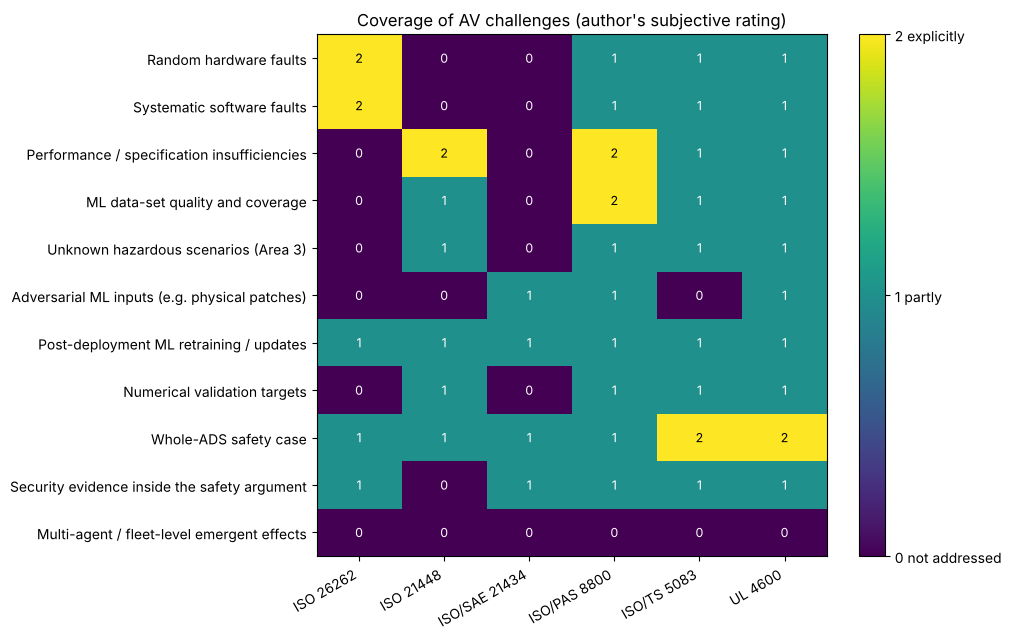

Challenges with no explicit coverage in any document (max rating < 2):
  - Unknown hazardous scenarios (Area 3) (best rating 1)
  - Adversarial ML inputs (e.g. physical patches) (best rating 1)
  - Post-deployment ML retraining / updates (best rating 1)
  - Numerical validation targets (best rating 1)
  - Security evidence inside the safety argument (best rating 1)
  - Multi-agent / fleet-level emergent effects (best rating 0)
Challenges explicitly covered by at least one document:
  - Random hardware faults: ISO 26262
  - Systematic software faults: ISO 26262
  - Performance / specification insufficiencies: ISO 21448, ISO/PAS 8800
  - ML data-set quality and coverage: ISO/PAS 8800
  - Whole-ADS safety case: ISO/TS 5083, UL 4600


In [2]:
docs = ["ISO 26262", "ISO 21448", "ISO/SAE 21434", "ISO/PAS 8800", "ISO/TS 5083", "UL 4600"]
coverage = pd.DataFrame({
    "Random hardware faults":                         [2, 0, 0, 1, 1, 1],
    "Systematic software faults":                     [2, 0, 0, 1, 1, 1],
    "Performance / specification insufficiencies":    [0, 2, 0, 2, 1, 1],
    "ML data-set quality and coverage":               [0, 1, 0, 2, 1, 1],
    "Unknown hazardous scenarios (Area 3)":           [0, 1, 0, 1, 1, 1],
    "Adversarial ML inputs (e.g. physical patches)":  [0, 0, 1, 1, 0, 1],
    "Post-deployment ML retraining / updates":        [1, 1, 1, 1, 1, 1],
    "Numerical validation targets":                   [0, 1, 0, 1, 1, 1],
    "Whole-ADS safety case":                          [1, 1, 1, 1, 2, 2],
    "Security evidence inside the safety argument":   [1, 0, 1, 1, 1, 1],
    "Multi-agent / fleet-level emergent effects":     [0, 0, 0, 0, 0, 0],
}, index=docs).T

fig, ax = plt.subplots(figsize=(10, 6.5))
im = ax.imshow(coverage.values, cmap="viridis", vmin=0, vmax=2, aspect="auto")
ax.set_xticks(range(len(docs)))
ax.set_xticklabels(docs, rotation=30, ha="right")
ax.set_yticks(range(len(coverage)))
ax.set_yticklabels(coverage.index)
for i in range(coverage.shape[0]):
    for j in range(coverage.shape[1]):
        v = coverage.values[i, j]
        ax.text(j, i, v, ha="center", va="center", color="black" if v == 2 else "white", fontsize=9)
cbar = fig.colorbar(im, ax=ax, ticks=[0, 1, 2])
cbar.ax.set_yticklabels(["0 not addressed", "1 partly", "2 explicitly"])
ax.set_title("Coverage of AV challenges (author's subjective rating)")
plt.tight_layout()
plt.show()

# Derived summary: which challenges does no document address explicitly?
best = coverage.max(axis=1)
print("Challenges with no explicit coverage in any document (max rating < 2):")
for ch in best[best < 2].index:
    print(f"  - {ch} (best rating {best[ch]})")
print("Challenges explicitly covered by at least one document:")
for ch in best[best == 2].index:
    print(f"  - {ch}: {', '.join(coverage.columns[coverage.loc[ch] == 2])}")

---

## 2. ISO 26262 gaps for ML

### What ISO 26262 assumes

1. **Requirements can be specified** completely enough to verify against.
2. **Verification methods** (reviews, requirements-based tests, structural coverage, analyses) apply to code whose logic is written by engineers.
3. **Failure modes can be analysed** (FMEA, FTA, DFA): random hardware faults *and* systematic faults.

### Why these assumptions are strained by ML

#### Gap 1: specification and verification of learned behaviour
- ISO 26262-6 verification methods assume specifiable, analysable software. A DNN's behaviour is defined by data and training, not by written logic.
- "This network will never miss a pedestrian" cannot be verified exhaustively. Evidence is statistical (test sets, scenario coverage) plus robustness analysis.
- On determinism: inference is normally deterministic for a fixed model and input. Stochastic elements such as dropout and random initialisation are training-time effects, unless the system deliberately uses stochastic inference (e.g. MC dropout for uncertainty). That case complicates reproducibility and verification.

#### Gap 2: data quality (now addressed by ISO/PAS 8800)
- ISO 26262 focuses on code and design quality (e.g. coding guidelines, reviews). It says nothing about **training data representing the ODD**.
- **ISO/PAS 8800:2024** now specifies data-set requirements and a data lifecycle for AI elements. The gap is narrower, but practitioners note that measuring representativeness remains hard (see Section 4).

#### Gap 3: post-deployment change
- ISO 26262-8 Clause 8 already requires change management and impact analysis for any modification, OTA updates included. UN R156 adds the regulatory layer.
- What is missing is guidance on **frequent ML retraining**: what amount of re-verification is proportionate when only the weights change?

#### Gap 4: hardware metrics vs ML "faults"
- For ASIL D, ISO 26262-5 sets hardware architectural metric targets of **SPFM ≥ 99 %** and **LFM ≥ 90 %**, plus a PMHF target (< 10⁻⁸ /h).
- These are hardware metrics. **No equivalent metric exists for ML insufficiencies.** What is the "diagnostic coverage" of an out-of-distribution monitor?
- Current practice uses uncertainty estimates and OOD detection as **monitors**, without an accepted way to quantify their coverage (see [OOD monitoring as a safety measure](../04_SOTIF_ISO21448/03_ood_monitoring_as_safety_measure.ipynb)).

#### Gap 5: adversarial robustness
- ISO 26262 covers random hardware and systematic faults. **Malicious inputs are out of its scope** and belong to ISO/SAE 21434, which does not specifically address ML attacks such as adversarial patches or data poisoning.

In [3]:
gaps_26262 = pd.DataFrame({
    "Gap": ["Specification/verification of learned behaviour", "Data quality and representativeness",
            "Post-deployment ML retraining", "Diagnostic coverage for ML insufficiencies",
            "Long-tail insufficiencies", "Adversarial robustness"],
    "ISO 26262 premise": ["Requirements-based verification of written logic", "Code/design quality",
                          "Change management per modification (Part 8)", "Hardware metrics SPFM/LFM/PMHF (Part 5)",
                          "FMEA/FTA of faults", "Random HW and systematic faults; malicious inputs out of scope"],
    "Situation for ML": ["Behaviour learned from data; exhaustive verification infeasible",
                         "Data quality often matters more than code", "Weights may change frequently",
                         "No accepted fault model for ML errors", "Unbounded rare conditions", "Adversarial examples exist"],
    "Where addressed now (as of Oct 2026)": ["ISO/PAS 8800 (AI V&V); ISO 26262 Ed. 3 in development",
                                             "ISO/PAS 8800 (data-set requirements)", "UN R156 + ISO 24089 (process); ML-specific guidance limited",
                                             "Open problem (monitors used as proxies)", "ISO 21448 (triggering conditions); ISO/PAS 8800",
                                             "ISO/SAE 21434 (generic); ML-specific attacks largely open"],
})
display(gaps_26262)
open_items = gaps_26262["Where addressed now (as of Oct 2026)"].str.contains("Open|open|limited")
print(f"{int(open_items.sum())} of {len(gaps_26262)} gaps are still described as open or only partly addressed.")

,Gap,ISO 26262 premise,Situation for ML,Where addressed now (as of Oct 2026)
0,Specification/verification of learned behaviour,Requirements-based verification of written logic,Behaviour learned from data; exhaustive verification infeasible,ISO/PAS 8800 (AI V&V); ISO 26262 Ed. 3 in development
1,Data quality and representativeness,Code/design quality,Data quality often matters more than code,ISO/PAS 8800 (data-set requirements)
2,Post-deployment ML retraining,Change management per modification (Part 8),Weights may change frequently,UN R156 + ISO 24089 (process); ML-specific guidance limited
3,Diagnostic coverage for ML insufficiencies,Hardware metrics SPFM/LFM/PMHF (Part 5),No accepted fault model for ML errors,Open problem (monitors used as proxies)
4,Long-tail insufficiencies,FMEA/FTA of faults,Unbounded rare conditions,ISO 21448 (triggering conditions); ISO/PAS 8800
5,Adversarial robustness,Random HW and systematic faults; malicious inputs out of scope,Adversarial examples exist,ISO/SAE 21434 (generic); ML-specific attacks largely open


3 of 6 gaps are still described as open or only partly addressed.


---

## 3. ISO 21448 (SOTIF) gaps

### What SOTIF addresses well
- **Functional insufficiencies**: sensor range, perception accuracy, algorithm limitations.
- **Known triggering conditions**: rain, fog, glare and similar.
- **Scenario-based evaluation** of known and unknown scenarios, plus **field monitoring** in operation (Clause 13).

### The four areas of ISO 21448

ISO 21448 partitions scenarios into four areas: **Area 1** known, not hazardous; **Area 2** known, hazardous; **Area 3** unknown, hazardous; **Area 4** unknown, not hazardous. The SOTIF activities aim to:

1. evaluate and reduce Area 2 (known hazardous scenarios) through functional modifications;
2. discover Area 3 scenarios, which moves them into Area 2, and reduce them;
3. show that the residual risk from Areas 2 and 3 meets the **acceptance criteria**.

**The gap:** the residual size of Area 3 cannot be measured directly.

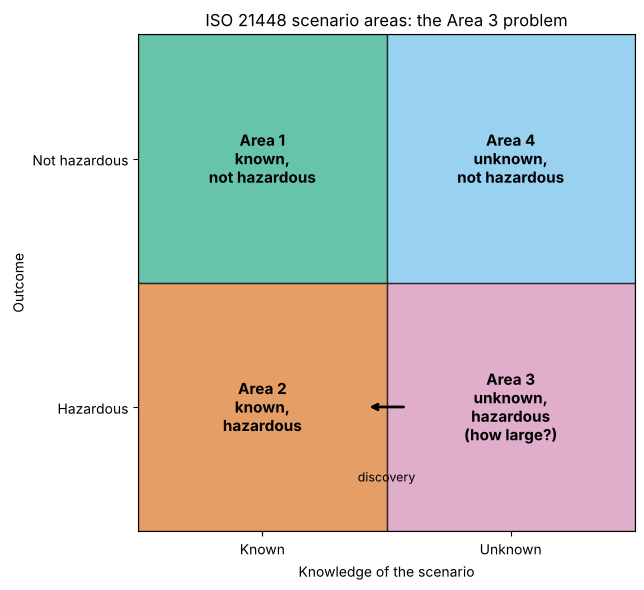

In [4]:
fig, ax = plt.subplots(figsize=(7, 6))
areas = [  # (x, y, colour, label)
    (0, 5, OI["green"], "Area 1\nknown,\nnot hazardous"),
    (0, 0, OI["vermillion"], "Area 2\nknown,\nhazardous"),
    (5, 0, OI["purple"], "Area 3\nunknown,\nhazardous\n(how large?)"),
    (5, 5, OI["sky"], "Area 4\nunknown,\nnot hazardous"),
]
for x, y, c, label in areas:
    ax.add_patch(Rectangle((x, y), 5, 5, facecolor=c, alpha=0.6, edgecolor="black"))
    ax.text(x + 2.5, y + 2.5, label, ha="center", va="center", fontsize=11, fontweight="bold")
ax.annotate("", xy=(4.6, 2.5), xytext=(5.4, 2.5), arrowprops=dict(arrowstyle="->", lw=2))
ax.text(5.0, 1.0, "discovery", ha="center", fontsize=9)
ax.set_xlim(0, 10)
ax.set_ylim(0, 10)
ax.set_aspect("equal")
ax.set_xticks([2.5, 7.5])
ax.set_xticklabels(["Known", "Unknown"])
ax.set_yticks([2.5, 7.5])
ax.set_yticklabels(["Hazardous", "Not hazardous"])
ax.set_xlabel("Knowledge of the scenario")
ax.set_ylabel("Outcome")
ax.set_title("ISO 21448 scenario areas: the Area 3 problem")
plt.tight_layout()
plt.show()

#### Gap 1: validation targets have no prescribed values
- ISO 21448 **does** require acceptance criteria and validation targets (e.g. derived from human-driver statistics or principles such as GAMAB or ALARP, discussed in its informative annexes). It leaves their **values** to the developer and regulator.
- Showing that a target is met with statistical confidence can need enormous exposure. A fleet that has driven 10⁸ km with zero relevant events only bounds the rate below about 3×10⁻⁸ /km at 95 % confidence (see [statistical safety validation](../06_AI_Safety_ISO_PAS_8800/08_statistical_safety_validation.ipynb)).
- Combining simulation, scenario-based testing and field data into one quantitative argument has no agreed method.

#### Gap 2: adversarial scenarios
- ISO 21448 excludes malicious actions, which belong to ISO/SAE 21434.
- Physical adversarial patterns (e.g. stickers on signs) sit **between** the two standards. They exploit a perception insufficiency (a SOTIF concern) through deliberate action (a 21434 concern).
- Arguing jointly about security and safety evidence for AI perception is one way to bridge the two. One proposal is a GSN pattern that integrates cybersecurity into the AI safety assurance argument (Patel & Jung, 2026); see [Notebook 4](04_safety_case_gsn.ipynb).

#### Gap 3: multi-agent interactions
- SOTIF analyses the ego vehicle's intended functionality in its environment. **Emergent fleet effects**, where many identical AVs make correlated errors, are not addressed by any of the documents in Section 1.
- Example (hypothetical): AV #1 brakes for a shadow; AV #2, following, brakes too; a human driver behind overtakes dangerously. The crash arises from the interaction, not from a single failure.

#### Gap 4: continuous development
- ISO 21448 is **not** "validate once, then done": Clause 13 requires operation-phase monitoring and feedback.
- What is missing is guidance for **frequent ML retraining** and gradual **ODD expansion**. How much of the SOTIF evidence remains valid after an update?

A systematic literature review of SOTIF for automated driving by the author and colleagues maps where research addresses these open points (Patel, Jung & Khatun, 2025).

---

## 4. Open research problems

### Problem 1: formal verification of neural networks
- **Goal:** prove properties such as local robustness: no label change within an ε-ball around an input.
- **State of the art:** modern verifiers handle networks far larger than the toy sizes of a decade ago. Examples are α,β-CROWN and Marabou, benchmarked in the annual VNN-COMP; they can check *local* robustness properties of sizeable CNNs.
- **Open problem:** specifying **semantic, ODD-level** properties ("all pedestrians in this ODD are detected") in a verifiable form, and scaling to full perception pipelines.

### Problem 2: measuring data-set representativeness
- **Question:** "Does my data set represent the ODD and its triggering conditions?"
- **Current state:** ISO/PAS 8800 requires data-set specifications. Quantitative coverage metrics for high-dimensional inputs remain research topics, for example ODD-attribute coverage, distribution-shift detection and active learning for gaps.

### Problem 3: safety validation at scale
- **Kalra & Paddock (2016):** demonstrating that an AV fleet's fatality rate is 20 % lower than the human rate would need about **11 billion miles** of driving, at 95 % confidence and 80 % power. That is roughly **500 years for a 100-vehicle fleet** driving continuously at 25 mph.
- **Approaches:** scenario-based testing (ISO 34502), simulation with credibility assessment (also required by the UN ADS Regulation), and field monitoring with safety performance indicators (UL 4600).
- **Open problem:** an accepted method to combine these sources of evidence into one statistical argument.

### Problem 4: continual learning and safety
- **Current practice:** no production AV is publicly known to learn online in the vehicle. Fleet data are used for **offline retraining**, and new models are released by OTA update after validation, under UN R156 where it applies.
- **Open problem:** proportionate re-validation for frequent model updates, and safeguards against catastrophic forgetting and data poisoning in the retraining pipeline.

### Problem 5: multi-agent safety
- Correlated behaviour of many identical AVs (common-cause insufficiencies), and adversaries who exploit predictable AV behaviour.
- Game-theoretic and traffic-simulation models exist; there is no validation methodology or standard.

### Problem 6: ethical decision-making
- Dilemma situations ("trolley problems") are rare, but they raise the question of who sets the decision rules.
- **Guidance exists:** the German Ethics Commission on Automated and Connected Driving (2017) recommends, among its 20 rules, that distinctions based on personal features (age, gender and so on) be prohibited. The EU Commission expert group report on the ethics of connected and automated vehicles (2020) makes 20 recommendations.
- **Gap:** no technical standard specifies how such principles become verifiable requirements.

### Problem 7: long-term validity
- The world changes: new vehicle designs, road markings, e-scooters. Models trained on past data may degrade through **distribution shift**.
- Hardware ageing (e.g. memory bit flips affecting weights) is a random hardware fault. It falls under ISO 26262 and the hardware aspects of ISO/PAS 8800.
- **Gap:** methods to monitor and bound performance drift over a vehicle's life. UL 4600 SPIs and ISO 21448 field monitoring provide a framework, not the method.

,Research problem,Why it matters,State of practice (as of Oct 2026),Author's severity rating (1-10)
0,Formal verification of NNs,Exhaustive testing impossible,Local robustness verifiable for sizeable CNNs; semantic properties open,9
1,Data-set representativeness,Unrepresentative data -> field insufficiencies,PAS 8800 data requirements; coverage metrics research,8
2,Safety validation at scale,Billions of miles for fatality-rate claims,Scenario-based + simulation + field data; no agreed combination,10
3,Continual learning safety,Updates can degrade safety,Offline retraining + OTA under R156,8
4,Multi-agent interactions,Correlated fleet errors,"Models exist, no validation method",7
5,Ethical decision rules,Societal acceptance and liability,"Ethics guidelines (DE 2017, EU 2020); no technical standard",6
6,Long-term validity (drift),Performance drift over years,Field monitoring and SPIs; no drift-bounding method,7


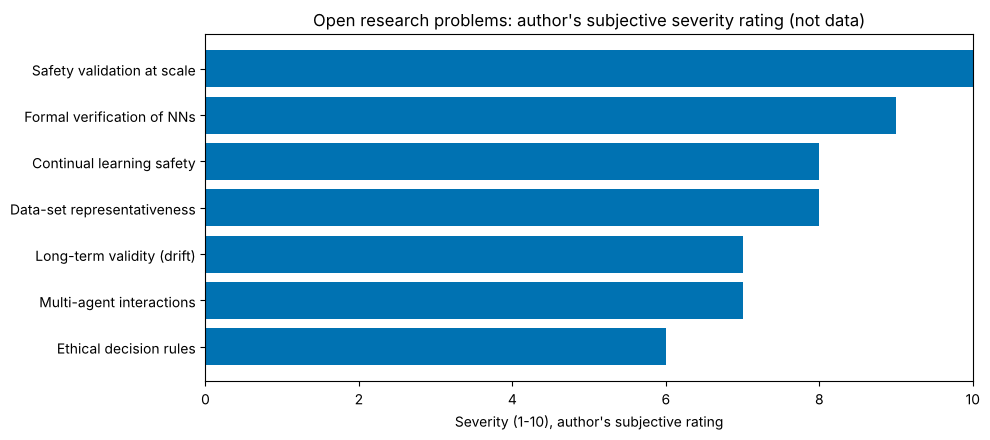

Highest-rated open problem (author's rating): Safety validation at scale (10/10).


In [5]:
SEV = "Author's severity rating (1-10)"
problems = pd.DataFrame({
    "Research problem": ["Formal verification of NNs", "Data-set representativeness", "Safety validation at scale",
                         "Continual learning safety", "Multi-agent interactions", "Ethical decision rules",
                         "Long-term validity (drift)"],
    "Why it matters": ["Exhaustive testing impossible", "Unrepresentative data -> field insufficiencies",
                       "Billions of miles for fatality-rate claims", "Updates can degrade safety",
                       "Correlated fleet errors", "Societal acceptance and liability", "Performance drift over years"],
    "State of practice (as of Oct 2026)": ["Local robustness verifiable for sizeable CNNs; semantic properties open",
                                           "PAS 8800 data requirements; coverage metrics research",
                                           "Scenario-based + simulation + field data; no agreed combination",
                                           "Offline retraining + OTA under R156",
                                           "Models exist, no validation method",
                                           "Ethics guidelines (DE 2017, EU 2020); no technical standard",
                                           "Field monitoring and SPIs; no drift-bounding method"],
    SEV: [9, 8, 10, 8, 7, 6, 7],
})
display(problems)

fig, ax = plt.subplots(figsize=(10, 4.5))
order = problems.sort_values(SEV)
ax.barh(order["Research problem"], order[SEV], color=OI["blue"])
ax.set_xlabel("Severity (1-10), author's subjective rating")
ax.set_xlim(0, 10)
ax.set_title("Open research problems: author's subjective severity rating (not data)")
plt.tight_layout()
plt.show()

top = problems.loc[problems[SEV].idxmax()]
print(f"Highest-rated open problem (author's rating): {top['Research problem']} ({top[SEV]}/10).")

---

## 5. Emerging and recently published documents

#### ISO/PAS 8800:2024: road vehicles, safety and AI
- **Status:** published December 2024 as a Publicly Available Specification. A PAS is a pre-standard; conversion to an International Standard and alignment with the EU AI Act's future harmonised standards are open.
- **Coverage:** AI safety lifecycle, AI safety requirements, data-set requirements, AI-specific analysis, V&V, assurance argument and operation-phase monitoring.

#### ISO/TS 5083:2025: safety for automated driving systems
- **Status:** published April 2025 as a Technical Specification.
- **Coverage:** safety by design, verification and validation, post-deployment activities and the safety argument for Level 3 and Level 4 features. It includes some cybersecurity considerations.

#### UL 4600 (3rd ed., 2023)
- **History:** Ed. 1 (2020), Ed. 2 (2022), Ed. 3 (March 2023). Ed. 3 added trucking-specific content, a more precise definition of safety performance indicators (SPIs), and post-incident behaviour requirements.
- **Approach:** goal-based safety case ("show that it is safe enough" rather than "follow these steps").

#### ISO/IEC TR 5469:2024: AI and functional safety
- An informative **technical report** (cross-sector). It gives guidance and states no requirements.

#### ISO 34500-series: scenarios and ODD
- ISO 34501 covers vocabulary, ISO 34502 the scenario-based safety evaluation framework, ISO 34503 ODD specification (scenery, environmental conditions, dynamic elements), and ISO 34504 scenario categorisation.
- These documents describe scenarios and ODDs. They do not set coverage targets.

#### Regulation closing a gap: the UN ADS Regulation (June 2026)
- It requires a safety management system, a safety case, credible (including virtual) testing, in-service monitoring and data recording. This turns the "require safety cases" recommendation of earlier years into binding regulation for Contracting Parties that apply it (see [Notebook 2](02_regulation_and_type_approval.ipynb)).

### What is still missing (author's view)
1. **Numerical validation methodology:** combining simulation, test-track, scenario and field evidence into a quantitative residual-risk argument.
2. **Proportionate re-validation for ML updates:** how much evidence must be regenerated after retraining.
3. **Coverage metrics for ML monitors:** an equivalent of diagnostic coverage for OOD and uncertainty monitors.
4. **Fleet-level and multi-agent safety:** correlated insufficiencies across identical vehicles.
5. **Integrated safety and security arguments for AI:** for example, how adversarial-robustness evidence supports safety claims.

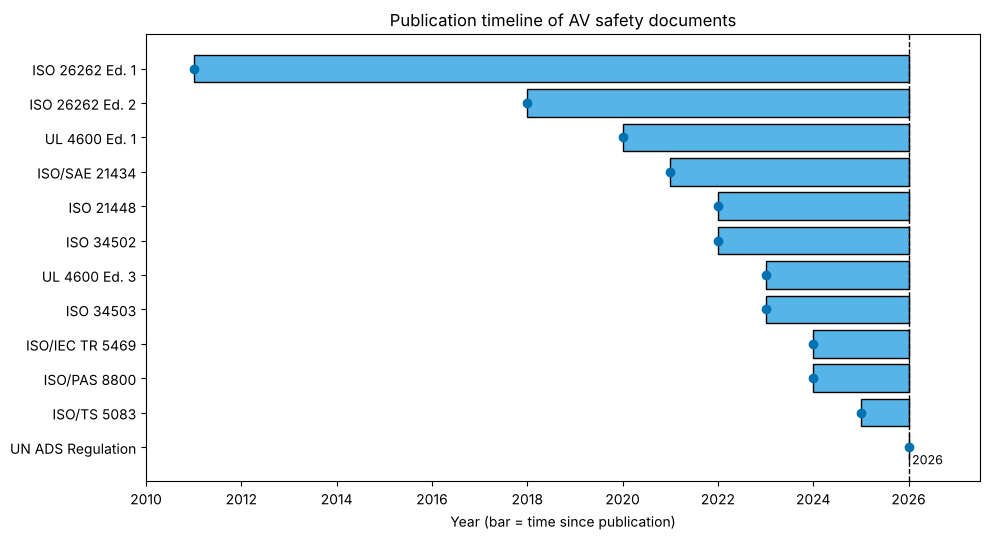

4 of 12 documents listed were published in 2024 or later: ISO/IEC TR 5469, ISO/PAS 8800, ISO/TS 5083, UN ADS Regulation
Not plotted: ISO 26262 Ed. 3 (in development; publication reported for around 2028, date not final; working-draft stage per ISO catalogue, Oct 2026).


In [6]:
pubs = pd.DataFrame([
    ("ISO 26262 Ed. 1", 2011), ("ISO 26262 Ed. 2", 2018), ("UL 4600 Ed. 1", 2020),
    ("ISO/SAE 21434", 2021), ("ISO 21448", 2022), ("ISO 34502", 2022), ("UL 4600 Ed. 3", 2023),
    ("ISO 34503", 2023), ("ISO/IEC TR 5469", 2024), ("ISO/PAS 8800", 2024), ("ISO/TS 5083", 2025),
    ("UN ADS Regulation", 2026),
], columns=["Document", "Year"]).sort_values("Year").reset_index(drop=True)
this_year = date.today().year

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh(pubs["Document"], [max(0, this_year - y) for y in pubs["Year"]], left=pubs["Year"],
        color=OI["sky"], edgecolor="black")
ax.scatter(pubs["Year"], pubs["Document"], color=OI["blue"], zorder=3)
ax.axvline(this_year, color="black", ls="--", lw=1)
ax.text(this_year, len(pubs) - 0.5, f" {this_year}", fontsize=9)
ax.invert_yaxis()
ax.set_xlabel("Year (bar = time since publication)")
ax.set_xlim(2010, this_year + 1.5)
ax.set_title("Publication timeline of AV safety documents")
plt.tight_layout()
plt.show()

recent = pubs[pubs["Year"] >= 2024]
print(f"{len(recent)} of {len(pubs)} documents listed were published in 2024 or later: "
      + ", ".join(recent["Document"]))
print("Not plotted: ISO 26262 Ed. 3 (in development; publication reported for around 2028, date not final; "
      "working-draft stage per ISO catalogue, Oct 2026).")

---

## 6. Summary and critical thinking

### 1. Standards are necessary but not sufficient
- **Standards provide** common terminology, process frameworks, best practice and a basis for regulatory acceptance.
- **Standards do not provide** solutions to fundamental ML problems: exhaustive verification, numerical validation targets, or bounds on unknown scenarios.
- **Conclusion:** use the standards, but do not equate compliance with safety. Make the gaps explicit in the safety case.

### 2. What changed recently
- The AI-specific gap is narrower: **ISO/PAS 8800** covers the AI lifecycle and data.
- The ADS-level safety-case gap is narrower: **ISO/TS 5083**, **UL 4600** and the **UN ADS Regulation** (2026).
- ISO 26262 **Ed. 3** is in development; publication reported for around 2028, date not final.

### 3. What this means in practice
**Developers:**
1. Follow the standards as a baseline and go beyond them where they are silent.
2. Document the gaps and how you address them in the safety case.
3. Keep the ODD narrow, monitor in the field and use SPIs.

**Regulators and assessors:**
1. Treat standards compliance as the baseline, not complete proof.
2. Ask what is *not* covered.
3. Require safety cases, as the UN ADS Regulation now does.

**Researchers:** work on the gaps in Section 5, and engage with the standards committees.

> **Opinion, not fact:** predicting when these gaps will close is speculative. Earlier versions of this notebook gave year ranges; they have been removed because no evidence supports them.

## In industry

**Work product.** The tailoring and gap rationale in the safety plan and the safety case: a documented gap analysis for each applied standard (which clauses do not fit an ML component), the complementary methods chosen (e.g. ISO/PAS 8800, UL 4600, AMLAS, statistical validation) and an argument that they represent the state of the art.

**Who produces it.** The safety architect or functional safety manager, together with the AI safety lead; the independent assessor reviews it. A standards liaison tracks new editions and feeds field experience back to the committees.

**What reviewers and assessors look for**

- [ ] Every tailoring of, or deviation from, a standard is justified in writing.
- [ ] ML-specific gaps (data requirements, uncertainty, distribution shift) are addressed by named methods with evidence, not by a compliance claim.
- [ ] Unknown hazardous scenarios are argued with exploration effort and a residual-risk estimate.
- [ ] No overstated claims, such as "the neural network is ISO 26262 compliant".
- [ ] State-of-the-art references are dated; known open problems are recorded as assumptions or defeaters in the safety case.
- [ ] A process exists to re-assess the case when new editions appear (ISO 26262 Ed. 3, ISO/PAS 8800 as an International Standard).

---

## Key takeaways

- ISO 26262's methods assume specifiable, analysable software. ML components need complementary evidence, and **ISO/PAS 8800** now provides the framework for it.
- ISO 21448 requires acceptance criteria, validation targets and field monitoring (Clause 13), but does not prescribe values. The residual size of **Area 3** cannot be measured directly.
- Malicious inputs are out of scope for ISO 26262 and 21448. ML-specific attacks are only generically covered by ISO/SAE 21434, which leaves room for integrated safety–security arguments.
- Gaps that remain open: numerical validation methodology, proportionate re-validation after ML updates, coverage metrics for ML monitors, and fleet-level effects.
- Separate published facts (standard titles, dates, clauses) from opinion (severity ratings, forecasts) when you argue about the future of standards.

## Self-assessment

1. Which earlier "AI standard gap" is now addressed, and by which document?
2. Does ISO 21448 set quantitative validation targets? What does it require instead?
3. Why is "ISO 26262 requires deterministic behaviour for ASIL D" an inaccurate statement of the gap?
4. Why do physical adversarial patches fall "between" ISO 21448 and ISO/SAE 21434?
5. Give two regulatory or standards developments since 2024 that address the ADS safety case.

<details>
<summary>Answers</summary>

1. The AI-specific safety lifecycle and data requirements, by ISO/PAS 8800:2024. ADS-level safety argumentation is addressed by ISO/TS 5083:2025.
2. No fixed values. It requires the developer to define acceptance criteria and validation targets and to show that they are met, with examples of how to derive them in informative annexes.
3. ISO 26262 contains no such explicit clause. Its verification methods assume specifiable, analysable software. Fixed-model inference is normally deterministic, and the real issue is verifying learned behaviour.
4. They exploit a perception insufficiency (SOTIF) through deliberate action (cybersecurity). ISO 21448 excludes malicious actions, and ISO/SAE 21434 does not specifically address ML input attacks.
5. Any two of: ISO/TS 5083:2025; UL 4600 Ed. 3 (2023); the UN ADS Regulation adopted by WP.29 in June 2026; EU 2022/1426 as amended in 2026.
</details>

## References

### Standards and regulation
- ISO 26262:2018; ISO/WD 26262-1 (Ed. 3, under development): https://www.iso.org/standard/90020.html
- ISO 21448:2022; ISO/SAE 21434:2021; ISO/PAS 8800:2024 (https://www.iso.org/standard/83303.html); ISO/TS 5083:2025 (https://www.iso.org/standard/81920.html)
- ISO/IEC TR 5469:2024, *Artificial intelligence — Functional safety and AI systems*
- ISO 34502:2022; ISO 34503:2023
- UL 4600, 3rd ed. (2023). https://www.ul.com/news/ul-4600-edition-3-updates-incorporate-autonomous-trucking
- UNECE (2026). UN Regulation on Automated Driving Systems, adopted 24 June 2026. https://unece.org/sustainable-development/press/unece-adopts-first-ever-global-rules-allowing-fully-autonomous

### Research on gaps and open problems
- Koopman, P., Wagner, M. (2017). Autonomous Vehicle Safety: An Interdisciplinary Challenge. *IEEE Intelligent Transportation Systems Magazine*, 9(1), 90–96. https://doi.org/10.1109/MITS.2016.2583491
- Burton, S., Gauerhof, L., Sethy, B. B., Habli, I., Hawkins, R. (2019). Confidence Arguments for Evidence of Performance in Machine Learning for Highly Automated Driving Functions. SAFECOMP 2019 Workshops, LNCS 11699, Springer.
- Borg, M. et al. (2019). Safely Entering the Deep: A Review of Verification and Validation for Machine Learning and a Challenge Elicitation in the Automotive Industry. *Journal of Automotive Software Engineering*. arXiv:1812.05389
- Kalra, N., Paddock, S. M. (2016). Driving to safety. *Transportation Research Part A*, 94, 182–193. https://doi.org/10.1016/j.tra.2016.09.010
- Amodei, D. et al. (2016). Concrete Problems in AI Safety. arXiv:1606.06565
- Huang, X. et al. (2020). A survey of safety and trustworthiness of deep neural networks. *Computer Science Review*, 37, 100270. https://doi.org/10.1016/j.cosrev.2020.100270
- Ethics Commission on Automated and Connected Driving (2017). Report. Federal Ministry of Transport and Digital Infrastructure, Germany.
- European Commission (2020). *Ethics of Connected and Automated Vehicles: Recommendations on road safety, privacy, fairness, explainability and responsibility*. Publications Office of the EU.
- Patel, M., Jung, R., Khatun, M. (2025). A Systematic Literature Review on Safety of the Intended Functionality for Automated Driving Systems. SAE Technical Paper 2025-01-5030. https://doi.org/10.4271/2025-01-5030
- Patel, M., Jung, R. (2026). Integrating Cybersecurity Into the AI Safety Assurance Argument: A GSN Pattern for AI-Based Perception Components in Highly Automated Driving. In *Computer Safety, Reliability, and Security. SAFECOMP 2026 Workshops*, LNCS, pp. 763–779. Springer. https://doi.org/10.1007/978-3-032-35506-5_55

## Further practice

- Companion notebook: [Standards Summary](https://github.com/milinpatel07/AI-Perception-Safety-Workshop/blob/main/notebooks/13_standards_summary.ipynb) in the author's *AI Perception Safety Workshop* repository.

---
**Navigation:** ← [Regulation and type approval](02_regulation_and_type_approval.ipynb) · [Module index](README.md) · [Safety case with GSN](04_safety_case_gsn.ipynb) →